In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Styling for plots
sns.set_theme(style="whitegrid")

In [42]:
# ==========================================
# PHASE 2 & 3: DATA COLLECTION, CLEANING & PREPROCESSING
# ==========================================
print("--- 1. LOADING & PREPROCESSING DATA ---")
# Dataset load karein (ensure karein 'train_u6lujuX_CVtuZ9i.csv' wahi par ho)
df = pd.read_csv("train_u6lujuX_CVtuZ9i.csv")

# Dataset Shape & Columns Preview
print(f"Original Shape - Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# Drop unnecessary column
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# Handle missing values
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Loan_Amount_Term', 'Credit_History']:
    df[col] = df[col].fillna(df[col].mode()[0])
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

# Encoding Categorical Variables
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Married'] = df['Married'].map({'Yes': 1, 'No': 0})
df['Education'] = df['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df['Self_Employed'] = df['Self_Employed'].map({'Yes': 1, 'No': 0})
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(float)
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True)

print("Missing values after cleaning:\n", df.isnull().sum().sum())

--- 1. LOADING & PREPROCESSING DATA ---
Original Shape - Rows: 614, Columns: 13
Missing values after cleaning:
 0



--- 2. EXPLORATORY DATA ANALYSIS (EDA) ---


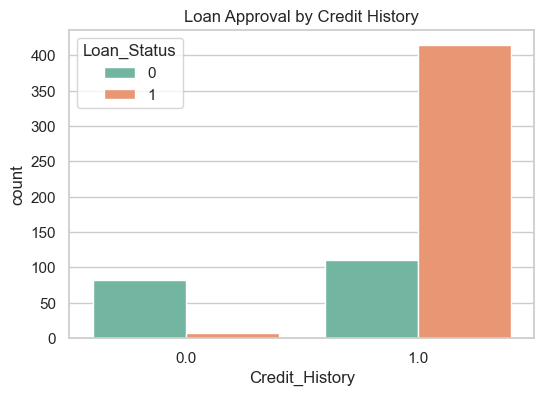

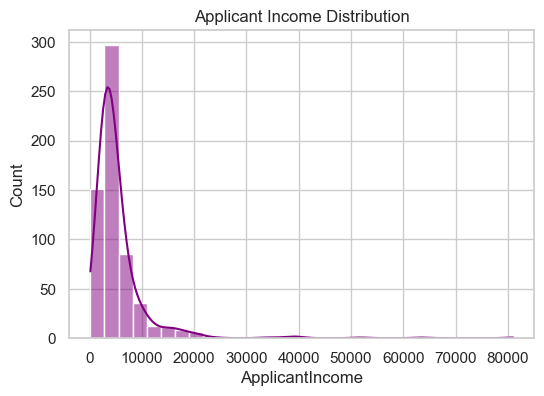


Correlation Matrix:
                     Gender   Married  Dependents  Education  Self_Employed  \
Gender             1.000000  0.364569    0.172914  -0.045364      -0.000525   
Married            0.364569  1.000000    0.334216  -0.012304       0.004489   
Dependents         0.172914  0.334216    1.000000  -0.055752       0.056798   
Education         -0.045364 -0.012304   -0.055752   1.000000       0.010383   
Self_Employed     -0.000525  0.004489    0.056798   0.010383       1.000000   
ApplicantIncome    0.058809  0.051708    0.118202   0.140760       0.127180   
CoapplicantIncome  0.082912  0.075948    0.030430   0.062290      -0.016100   
LoanAmount         0.106904  0.146546    0.163103   0.168759       0.115100   
Loan_Amount_Term  -0.074030 -0.100912   -0.103864   0.073928      -0.033739   
Credit_History     0.009170  0.010938   -0.040160   0.073658      -0.001550   
Loan_Status        0.017987  0.091478    0.010118   0.085884      -0.003700   

                   ApplicantIn

In [43]:
# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("\n--- 2. EXPLORATORY DATA ANALYSIS (EDA) ---")

# Visualization 1: Credit History vs Loan Status
plt.figure(figsize=(6, 4))
sns.countplot(x='Credit_History', hue='Loan_Status', data=df, palette='Set2')
plt.title('Loan Approval by Credit History')
plt.show()

# Visualization 2: Applicant Income Distribution
plt.figure(figsize=(6, 4))
sns.histplot(df['ApplicantIncome'], bins=30, kde=True, color='purple')
plt.title('Applicant Income Distribution')
plt.show()

# Correlation Matrix
print("\nCorrelation Matrix:")
numeric_df = df.select_dtypes(include=[np.number])
print(numeric_df.corr())

In [44]:
# ==========================================
# PHASE 5: MODEL TRAINING (LOGISTIC REGRESSION)
# ==========================================
print("\n--- 3. MODEL TRAINING ---")
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
print(f"Model Training Complete! Training Accuracy: {model.score(X_train_scaled, y_train) * 100:.2f}%")


--- 3. MODEL TRAINING ---
Model Training Complete! Training Accuracy: 82.08%


In [45]:
# ==========================================
# PHASE 6: MODEL EVALUATION
# ==========================================
print("\n--- 4. MODEL EVALUATION ---")
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Evaluation Metrics
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")


--- 4. MODEL EVALUATION ---
Confusion Matrix:
 [[18 25]
 [ 1 79]]

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123

Accuracy  : 0.7886
Precision : 0.7596
Recall    : 0.9875
F1-Score  : 0.8587
ROC-AUC   : 0.7404


In [46]:
# ==========================================
# PHASE 7: MAKING PREDICTIONS ON NEW TEST CASES
# ==========================================
print("\n--- 5. MAKING PREDICTIONS ON NEW TEST CASES ---")

def predict_loan_status(new_applicants_df):
    new_applicants_scaled = scaler.transform(new_applicants_df)
    preds = model.predict(new_applicants_scaled)
    probs = model.predict_proba(new_applicants_scaled)
    
    results = []
    for i, pred in enumerate(preds):
        status = "Approved (Y)" if pred == 1 else "Rejected (N)"
        prob_score = probs[i][pred] * 100
        results.append({
            "Applicant": i + 1,
            "Prediction": status,
            "Confidence Probability": f"{prob_score:.2f}%"
        })
    return pd.DataFrame(results)

# Sample new test cases matching training features structure
test_cases = pd.DataFrame([
    [1, 1, 0, 1, 0, 5000, 1500, 120.0, 360.0, 1.0, 1, 0], # Applicant 1
    [0, 0, 1, 0, 1, 2500, 0, 100.0, 180.0, 0.0, 0, 1],    # Applicant 2
    [1, 1, 2, 1, 0, 8500, 0, 200.0, 360.0, 1.0, 0, 0]     # Applicant 3
], columns=X.columns)

prediction_results = predict_loan_status(test_cases)
display(prediction_results)


--- 5. MAKING PREDICTIONS ON NEW TEST CASES ---


,Applicant,Prediction,Confidence Probability
0,1,Approved (Y),90.16%
1,2,Rejected (N),95.10%
2,3,Approved (Y),81.08%
